# NB17: Pipeline-Derived Longitudinal Connectomics

> **Local pipeline required.** This notebook requires SC/FC matrices from NB15--NB16 and cannot run in Google Colab. See NB00--NB06 and NB08 for Colab-compatible notebooks.

## Purpose

Compare pre-operative and post-operative structural and functional
connectivity computed from the pipeline outputs. Extends NB14
(voxel-level pre/post comparison) with network-level analysis.

### Relationship to NB06 and NB14

- **NB06** (Track A): Pre/post tumor impact using TVB-derived connectomes
- **NB14** (Track B): Voxel-level delta-FA/MD maps and ROI volumes
- **This notebook** (Track B): Network-level pre/post comparison using
  SC and FC matrices computed in NB15-NB16

Together, NB14 + NB17 provide the complete longitudinal picture:
voxel-level tissue changes AND network-level connectivity changes.

### What You Need

- FC matrices from NB15: `derivatives/connectivity/sub-{SUB}/ses-{SES}/fc_pearson.npy`
- SC matrices from NB16: `derivatives/connectivity/sub-{SUB}/ses-{SES}/sc_sift2.npy`
- Comparison report from NB14: `derivatives/registered_t1w/sub-{SUB}/preop_vs_postop/`

### Analysis Dimensions

1. **SC changes**: Which tracts were disrupted by surgery?
2. **FC changes**: Which functional connections weakened or strengthened?
3. **SC-FC coupling shift**: Did structure-function correspondence change?
4. **Hub disruption**: Were network hubs affected by tumor/resection?
5. **Brain mechanics implications**: How do connectivity changes map to
   altered mechanical load paths?

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import json

_cwd = Path.cwd().resolve()
REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

DERIV_ROOT = REPO_ROOT / 'derivatives'
CONN_DIR = DERIV_ROOT / 'connectivity'
REG_DIR = DERIV_ROOT / 'registered_t1w'

SUBJECTS = ['PAT16']

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

## 1. Load Pre-op and Post-op Connectivity Matrices

In [2]:
def load_matrices(sub):
    """Load SC and FC for both sessions of a subject."""
    result = {}
    for ses in ['preop', 'postop']:
        ses_dir = CONN_DIR / f'sub-{sub}' / f'ses-{ses}'
        data = {}

        fc_path = ses_dir / 'fc_pearson.npy'
        sc_path = ses_dir / 'sc_sift2.npy'
        names_path = ses_dir / 'fc_roi_names.json'

        if fc_path.exists():
            data['fc'] = np.load(str(fc_path))
        if sc_path.exists():
            data['sc'] = np.load(str(sc_path))
        if names_path.exists():
            with open(names_path) as f:
                data['names'] = json.load(f)

        if data:
            result[ses] = data

    return result

for sub in SUBJECTS:
    data = load_matrices(sub)
    print(f'\nsub-{sub}:')
    for ses, d in data.items():
        parts = []
        if 'fc' in d:
            parts.append(f'FC {d["fc"].shape}')
        if 'sc' in d:
            parts.append(f'SC {d["sc"].shape}')
        print(f'  ses-{ses}: {", ".join(parts) if parts else "not available"}')


sub-PAT16:
  ses-preop: FC (82, 82), SC (2035, 2035)
  ses-postop: FC (82, 82), SC (2035, 2035)


## 2. Delta-FC: Functional Connectivity Changes


sub-PAT16: delta-FC (82 ROIs)
  Mean: -0.0094, Std: 0.2039
  Weakened (delta < -0.1): 1057
  Strengthened (delta > 0.1): 978


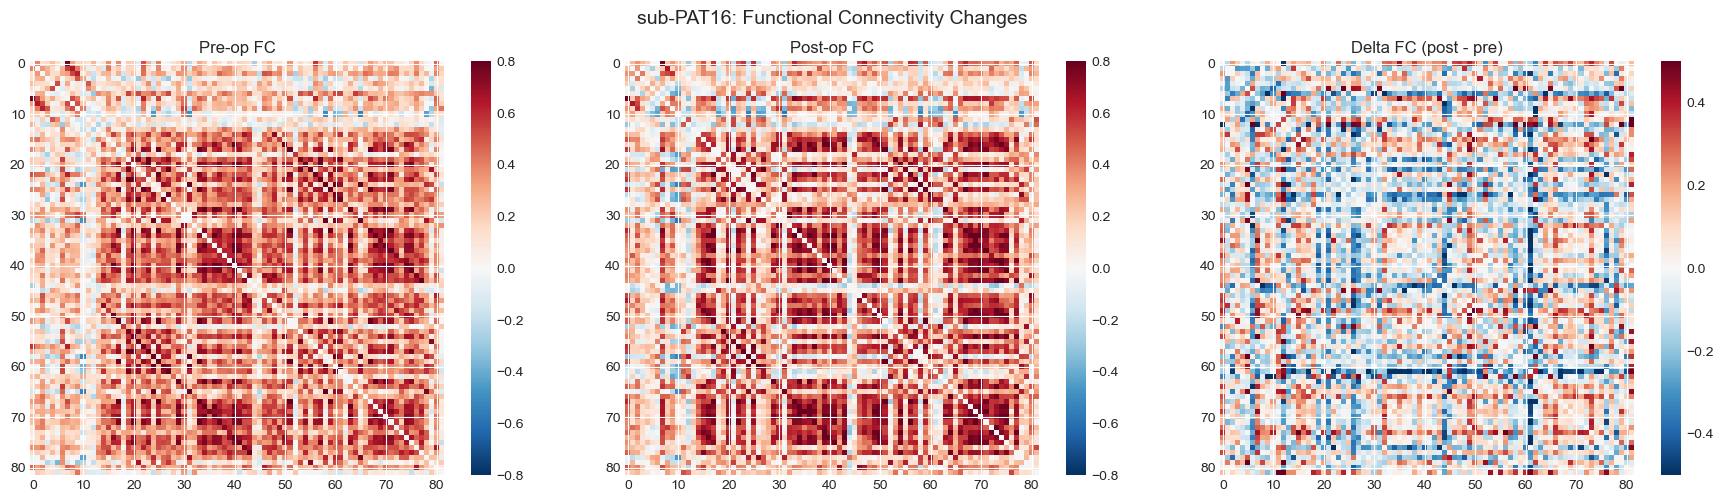

In [3]:
from scipy import stats

for sub in SUBJECTS:
    data = load_matrices(sub)
    if 'preop' not in data or 'postop' not in data:
        print(f'sub-{sub}: both sessions needed for comparison')
        continue
    if 'fc' not in data['preop'] or 'fc' not in data['postop']:
        print(f'sub-{sub}: FC not available for both sessions')
        continue

    fc_pre = data['preop']['fc']
    fc_post = data['postop']['fc']
    n = min(fc_pre.shape[0], fc_post.shape[0])
    fc_pre = fc_pre[:n, :n]
    fc_post = fc_post[:n, :n]

    delta_fc = fc_post - fc_pre
    idx = np.triu_indices(n, k=1)
    delta_vec = delta_fc[idx]

    n_weakened = int(np.sum(delta_vec < -0.1))
    n_strengthened = int(np.sum(delta_vec > 0.1))

    print(f'\nsub-{sub}: delta-FC ({n} ROIs)')
    print(f'  Mean: {np.mean(delta_vec):.4f}, Std: {np.std(delta_vec):.4f}')
    print(f'  Weakened (delta < -0.1): {n_weakened}')
    print(f'  Strengthened (delta > 0.1): {n_strengthened}')

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    im0 = axes[0].imshow(fc_pre, cmap='RdBu_r', vmin=-0.8, vmax=0.8)
    axes[0].set_title(f'Pre-op FC')
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    im1 = axes[1].imshow(fc_post, cmap='RdBu_r', vmin=-0.8, vmax=0.8)
    axes[1].set_title(f'Post-op FC')
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    im2 = axes[2].imshow(delta_fc, cmap='RdBu_r', vmin=-0.5, vmax=0.5)
    axes[2].set_title(f'Delta FC (post - pre)')
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    fig.suptitle(f'sub-{sub}: Functional Connectivity Changes', fontsize=14)
    plt.tight_layout()
    plt.show()

## 3. Delta-SC: Structural Connectivity Changes


sub-PAT16: delta-SC (2035 nodes)
  Top strength losses: nodes [  42 2007 1028   10   49] (delta=[-0.00932477 -0.00423071 -0.00350873 -0.00305462 -0.00294177])
  Top strength gains:  nodes [2027   15   46   40    7] (delta=[0.00368089 0.0038045  0.00655984 0.00739199 0.00945447])


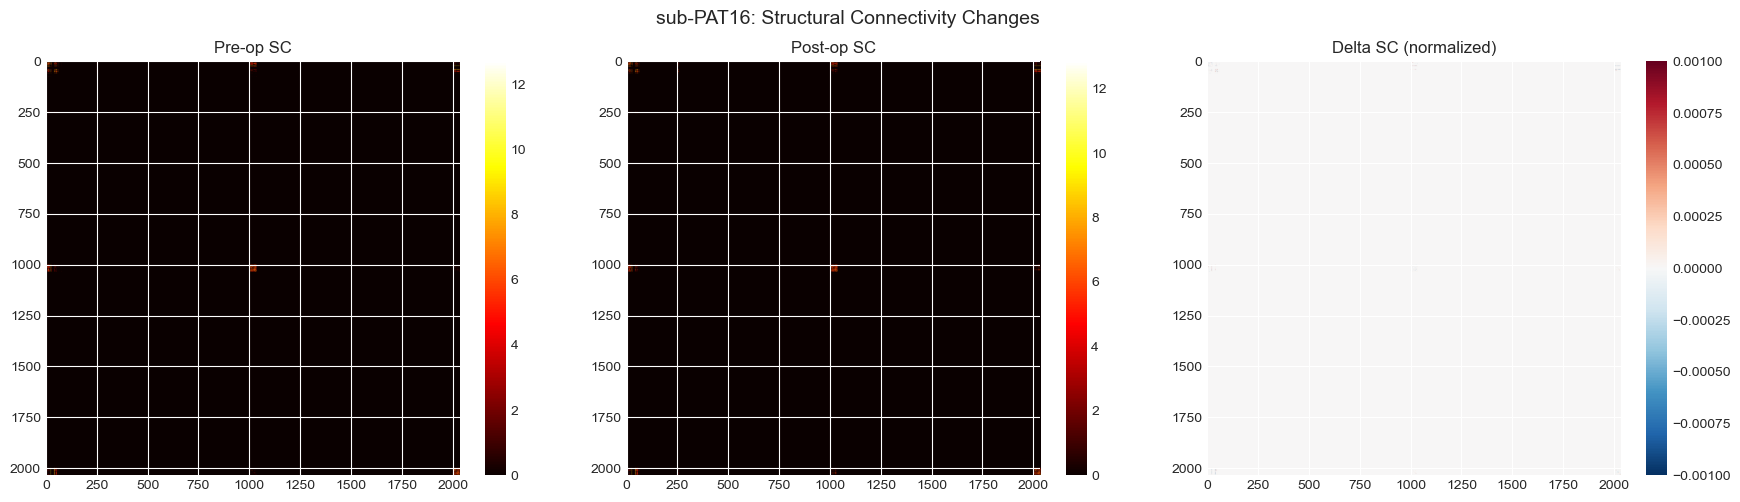

In [4]:
for sub in SUBJECTS:
    data = load_matrices(sub)
    if 'preop' not in data or 'postop' not in data:
        continue
    if 'sc' not in data['preop'] or 'sc' not in data['postop']:
        print(f'sub-{sub}: SC not available for both sessions')
        continue

    sc_pre = data['preop']['sc']
    sc_post = data['postop']['sc']
    n = min(sc_pre.shape[0], sc_post.shape[0])
    sc_pre = sc_pre[:n, :n]
    sc_post = sc_post[:n, :n]

    # Normalize for comparison
    sc_pre_n = sc_pre / sc_pre.sum() if sc_pre.sum() > 0 else sc_pre
    sc_post_n = sc_post / sc_post.sum() if sc_post.sum() > 0 else sc_post
    delta_sc = sc_post_n - sc_pre_n

    # Node-level strength change
    strength_pre = sc_pre_n.sum(axis=1)
    strength_post = sc_post_n.sum(axis=1)
    delta_strength = strength_post - strength_pre

    top_loss = np.argsort(delta_strength)[:5]
    top_gain = np.argsort(delta_strength)[-5:]

    print(f'\nsub-{sub}: delta-SC ({n} nodes)')
    print(f'  Top strength losses: nodes {top_loss} (delta={delta_strength[top_loss]})')
    print(f'  Top strength gains:  nodes {top_gain} (delta={delta_strength[top_gain]})')

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, mat, title in zip(axes,
            [np.log1p(sc_pre), np.log1p(sc_post), delta_sc],
            ['Pre-op SC', 'Post-op SC', 'Delta SC (normalized)']):
        if 'Delta' in title:
            im = ax.imshow(mat, cmap='RdBu_r', vmin=-0.001, vmax=0.001)
        else:
            im = ax.imshow(mat, cmap='hot')
        ax.set_title(title)
        plt.colorbar(im, ax=ax, fraction=0.046)

    fig.suptitle(f'sub-{sub}: Structural Connectivity Changes', fontsize=14)
    plt.tight_layout()
    plt.show()

## 4. SC-FC Coupling Shift

Compare the structure-function relationship before and after surgery.

In [5]:
for sub in SUBJECTS:
    data = load_matrices(sub)
    coupling = {}

    for ses in ['preop', 'postop']:
        if ses not in data or 'sc' not in data[ses] or 'fc' not in data[ses]:
            continue
        sc = data[ses]['sc']
        fc = data[ses]['fc']
        n = min(sc.shape[0], fc.shape[0])

        idx = np.triu_indices(n, k=1)
        sc_vec = np.log1p(sc[:n, :n][idx])
        fc_vec = fc[:n, :n][idx]
        mask = np.isfinite(sc_vec) & np.isfinite(fc_vec)

        if mask.sum() > 10:
            r, p = stats.pearsonr(sc_vec[mask], fc_vec[mask])
            coupling[ses] = r

    if len(coupling) == 2:
        print(f'sub-{sub}: SC-FC coupling')
        print(f'  Pre-op:  r = {coupling["preop"]:.3f}')
        print(f'  Post-op: r = {coupling["postop"]:.3f}')
        print(f'  Change:  delta-r = {coupling["postop"] - coupling["preop"]:.3f}')
        if coupling['postop'] < coupling['preop']:
            print('  -> Reduced coupling: functional connectivity less constrained '
                  'by structural connectivity after surgery')
        else:
            print('  -> Increased coupling: functional connectivity more aligned '
                  'with structural connectivity after surgery')

sub-PAT16: SC-FC coupling
  Pre-op:  r = -0.048
  Post-op: r = -0.021
  Change:  delta-r = 0.027
  -> Increased coupling: functional connectivity more aligned with structural connectivity after surgery


## 5. Integration with Voxel-Level and Deformation Changes (NB14)

Combine network-level connectivity changes with the voxel-level
delta-FA/MD maps and deformation field outputs from NB14. When Step 5b
(longitudinal registration) has been run, the comparison uses warped
pre-op data for proper voxel correspondence, and displacement/Jacobian
maps provide empirical tissue deformation data.

In [6]:
for sub in SUBJECTS:
    report_path = REG_DIR / f'sub-{sub}' / 'preop_vs_postop' / 'comparison_report.json'
    data = load_matrices(sub)

    print(f'\n{"=" * 60}')
    print(f' sub-{sub}: Integrated Longitudinal Summary')
    print(f'{"=" * 60}')

    # Voxel-level (from NB14)
    if report_path.exists():
        with open(report_path) as f:
            report = json.load(f)
        analyses = report.get('analyses', {})
        has_long = report.get('has_longitudinal', False)
        if has_long:
            print(f'  (using warped pre-op data from longitudinal registration)')
        if 'delta_fa' in analyses:
            fa = analyses['delta_fa']
            print(f'  Voxel-level delta-FA: mean={fa["mean"]:.4f} '
                  f'(negative = fiber disruption)')
        if 'delta_md' in analyses:
            md = analyses['delta_md']
            print(f'  Voxel-level delta-MD: mean={md["mean"]:.6f} '
                  f'(positive = increased water content)')
        if 'displacement' in analyses:
            d = analyses['displacement']
            print(f'  Displacement: mean={d["mean_mm"]:.2f} mm, '
                  f'max={d["max_mm"]:.2f} mm, 95th={d["p95_mm"]:.2f} mm')
        if 'jacobian' in analyses:
            j = analyses['jacobian']
            print(f'  Jacobian: mean={j["mean"]:.4f}, '
                  f'expanding={j["pct_expanding"]:.1f}%, '
                  f'contracting={j["pct_contracting"]:.1f}%')
        if 'cavity' in analyses:
            c = analyses['cavity']
            print(f'  Cavity: {c["volume_cm3"]:.1f} cm3')
    else:
        print('  Voxel-level: run compare_preop_postop.py first')

    # Network-level
    if 'preop' in data and 'postop' in data:
        if 'fc' in data['preop'] and 'fc' in data['postop']:
            fc_pre = data['preop']['fc']
            fc_post = data['postop']['fc']
            n = min(fc_pre.shape[0], fc_post.shape[0])
            delta = fc_post[:n, :n] - fc_pre[:n, :n]
            idx = np.triu_indices(n, k=1)
            print(f'  Network-level delta-FC: mean={np.mean(delta[idx]):.4f}, '
                  f'weakened={int(np.sum(delta[idx] < -0.1))}, '
                  f'strengthened={int(np.sum(delta[idx] > 0.1))}')
        if 'sc' in data['preop'] and 'sc' in data['postop']:
            sc_pre = data['preop']['sc']
            sc_post = data['postop']['sc']
            n = min(sc_pre.shape[0], sc_post.shape[0])
            s_pre = sc_pre[:n, :n].sum()
            s_post = sc_post[:n, :n].sum()
            pct = 100 * (s_post - s_pre) / s_pre if s_pre > 0 else 0
            print(f'  Network-level SC: total weight change = {pct:+.1f}%')
    else:
        print('  Network-level: run NB15 and NB16 first')


 sub-PAT16: Integrated Longitudinal Summary
  (using warped pre-op data from longitudinal registration)
  Voxel-level delta-FA: mean=0.0001 (negative = fiber disruption)
  Voxel-level delta-MD: mean=0.000057 (positive = increased water content)
  Displacement: mean=1.83 mm, max=13.02 mm, 95th=6.16 mm
  Jacobian: mean=1.0000, expanding=24.6%, contracting=29.7%
  Cavity: 18.6 cm3
  Network-level delta-FC: mean=-0.0094, weakened=1057, strengthened=978
  Network-level SC: total weight change = -2.6%


## 6. Brain Mechanics Implications

The combined voxel-level, deformation, and network-level changes inform the FE model:

| Change | Source | Mechanical Impact |
|--------|--------|------------------|
| Displacement field u(x) | Step 5b SyN | Empirical tissue motion for FE validation |
| Jacobian J(x) | Step 5b SyN | Local volume change (compressibility) |
| Cavity mask | Step 5b | Non-simply-connected domain, zero-stiffness BC |
| Decreased FA near cavity | NB14 delta maps | Loss of anisotropic stiffness |
| Increased MD (edema) | NB14 delta maps | Increased tissue compliance |
| SC edge loss | NB17 delta-SC | Modified load transmission paths |
| FC network reorganization | NB17 delta-FC | Altered functional constraints |
| Reduced SC-FC coupling | NB17 coupling shift | Less predictable functional response |

The displacement field from Step 5b provides ground-truth deformation data
that can directly validate FE model predictions of brain shift. These outputs
feed into NB07 (FEniCSx mesh with updated material properties) and NB08
(coupled TVB-FEniCSx with updated connectivity).